# ModelAtlas: exploring the model graph

A short, read-only tour of model families, licenses and training datasets.
Run all cells from the repository root with the Neo4j database and API running.
Install `requirements-notebook.txt` with **Python 3.12 or newer**.

The saved run uses the full graph, not the small test fixture. Its dataset-card
loader is PR #5 at commit `4a8966dddcfe478805a3fdddde8e8f7cef9922f6`.
The two downloaded data revisions are shown below. This draft should be merged
after #5, #7 and #8; it does not merge those PRs itself.

## 1. Setup

The password comes from `.env` or the environment and is never displayed.
Defaults are `bolt://localhost:7687` and `http://127.0.0.1/api`.
Set `NEO4J_NOTEBOOK_URI` and `MODELATLAS_API_URL` to use other local ports.
Reads use READ sessions, a 10-second query timeout and bounded result lists.

In [1]:
from time import perf_counter

started = perf_counter()

import json
import os
import platform
from pathlib import Path
from urllib.parse import quote
from typing import Any

import matplotlib
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
import requests
from dotenv import dotenv_values
from IPython.display import display
from neo4j import READ_ACCESS, GraphDatabase, Query

get_ipython().run_line_magic("matplotlib", "inline")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

root = Path.cwd()
config = dotenv_values(root / ".env")
password = os.getenv("NEO4J_PASSWORD") or config.get("NEO4J_PASSWORD")
if not password:
    raise RuntimeError("Set NEO4J_PASSWORD in .env before running this notebook.")
uri = os.getenv("NEO4J_NOTEBOOK_URI") or config.get("NEO4J_NOTEBOOK_URI", "bolt://localhost:7687")
user = os.getenv("NEO4J_USER") or config.get("NEO4J_USER", "neo4j")
database = os.getenv("NEO4J_DATABASE") or config.get("NEO4J_DATABASE", "neo4j")
api_url = os.getenv("MODELATLAS_API_URL") or config.get("MODELATLAS_API_URL", "http://127.0.0.1/api")
driver = GraphDatabase.driver(uri, auth=(user, password), connection_timeout=10)
driver.verify_connectivity()
http = requests.Session()
http.trust_env = False  # Local requests must not go through a system HTTP proxy.


def read(cypher: str, **params: Any) -> list[dict[str, Any]]:
    """Fetch a bounded query result through a read-only session."""
    with driver.session(database=database, default_access_mode=READ_ACCESS) as session:
        return session.run(Query(cypher, timeout=10), params).data()


def api(path: str, **params: Any) -> dict[str, Any]:
    """Call the running API, failing clearly on an unsuccessful response."""
    response = http.get(f"{api_url.rstrip('/')}/{path.lstrip('/')}", params=params, timeout=15)
    response.raise_for_status()
    return response.json()


assert api("/health")["status"] == "ok"
data_dir = Path(os.getenv("MODELATLAS_DATA_DIR") or config.get("MODELATLAS_DATA_DIR", root / "data"))
provenance = []
for source in ("model_cards", "dataset_cards"):
    manifest = data_dir / "raw" / source / "manifest.json"
    revision = (
        json.loads(manifest.read_text(encoding="utf-8"))["commit"] if manifest.exists() else "not available locally"
    )
    provenance.append({"source": source, "dump commit": revision})
display(pd.DataFrame(provenance))
print(f"Python {platform.python_version()} | matplotlib {matplotlib.__version__} | networkx {nx.__version__}")


,source,dump commit
0,model_cards,99b6ce9d9d47f796700745ed9630556c91c00439
1,dataset_cards,a20ebd23b0e74614bd0458f264e46b31df52718a


Python 3.12.14 | matplotlib 3.11.2 | networkx 3.7


## 2. Graph overview

These are counts from the live database. `Unlisted` is an extra label on
a `Model`, so label counts overlap and should not be added as distinct entities.
Relationships include the dataset-card links when the second source is loaded.

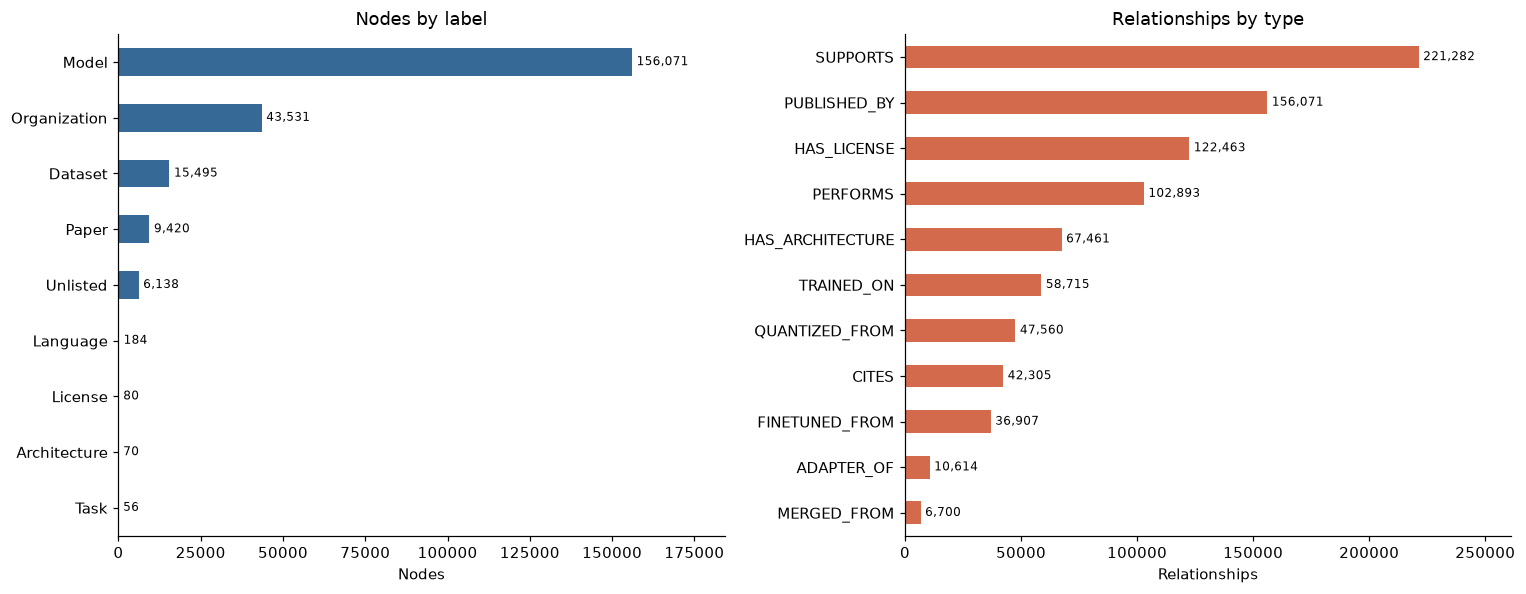

API and database agree: 156,071 Model nodes.


In [2]:
node_counts = pd.DataFrame(
    read(
        "MATCH (n) UNWIND labels(n) AS label RETURN label, count(*) AS nodes "
        "ORDER BY nodes DESC, label LIMIT $limit",
        limit=50,
    )
)
relation_counts = pd.DataFrame(
    read(
        "MATCH ()-[r]->() RETURN type(r) AS relation, count(*) AS links " "ORDER BY links DESC, relation LIMIT $limit",
        limit=50,
    )
)
assert not node_counts.empty and not relation_counts.empty, "Load the full graph before running the demo."
model_count = int(node_counts.set_index("label").loc["Model", "nodes"])
assert api("/stats")["models"] == model_count, "The API and driver must point to the same graph."

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
node_counts.iloc[::-1].plot.barh(x="label", y="nodes", ax=axes[0], color="#376996", legend=False)
relation_counts.iloc[::-1].plot.barh(x="relation", y="links", ax=axes[1], color="#d46a4c", legend=False)
axes[0].set(title="Nodes by label", xlabel="Nodes", ylabel="")
axes[1].set(title="Relationships by type", xlabel="Relationships", ylabel="")
for axis in axes:
    axis.bar_label(axis.containers[0], fmt="{:,.0f}", padding=3, fontsize=8)
axes[0].set_xlim(0, node_counts["nodes"].max() * 1.18)
axes[1].set_xlim(0, relation_counts["links"].max() * 1.18)
fig.tight_layout()
plt.show()
print(f"API and database agree: {model_count:,} Model nodes.")


## 3. Lineage statistics

`lineage_depth` is the longest chain above a model; roots have depth zero.
`descendant_count` counts distinct descendants and is precomputed during ETL.
Reading the stored value avoids traversing every family again in this demo.
The descendant chart uses powers-of-ten bins and a logarithmic count axis;
zero descendants have their own bin. The printed depth percentage describes this
loaded graph, so it can differ from the raw-dump profile in the reports.

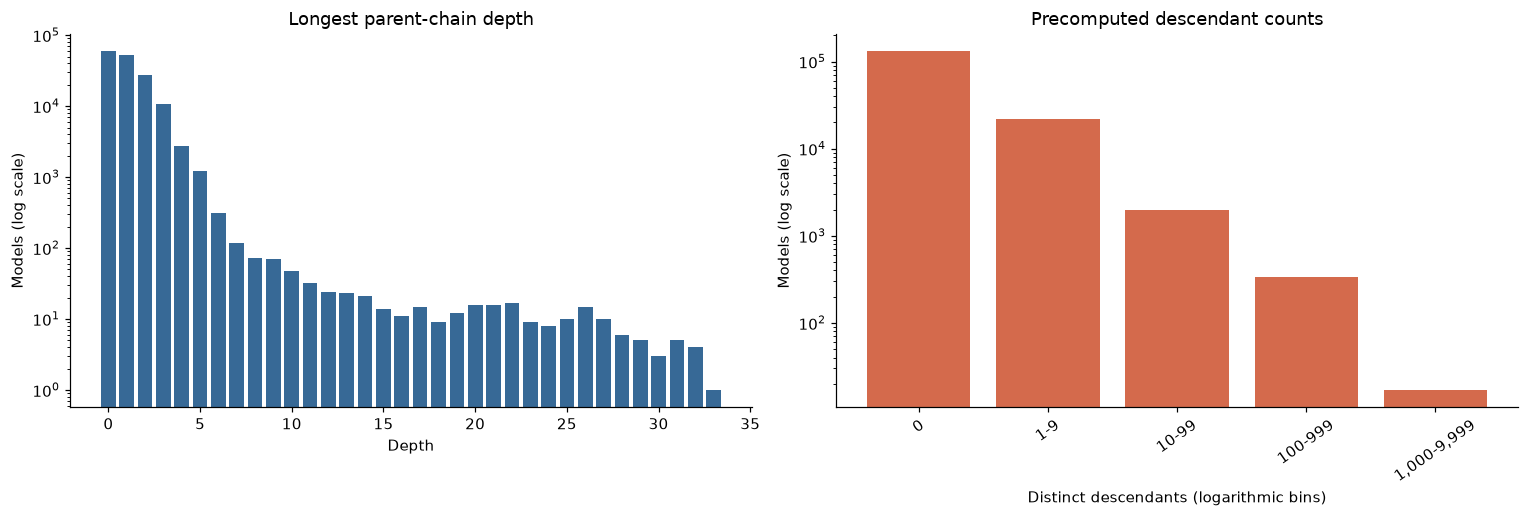

99.42% of models with a depth value have depth at most five.


In [3]:
depth_counts = pd.DataFrame(
    read(
        "MATCH (m:Model) WHERE m.lineage_depth IS NOT NULL "
        "RETURN m.lineage_depth AS depth, count(*) AS models ORDER BY depth LIMIT $limit",
        limit=200,
    )
)
descendant_bins = pd.DataFrame(
    read(
        "MATCH (m:Model) WHERE m.descendant_count IS NOT NULL "
        "WITH CASE WHEN m.descendant_count = 0 THEN 0 "
        "ELSE toInteger(floor(log10(toFloat(m.descendant_count)))) + 1 END AS bucket "
        "RETURN bucket, count(*) AS models ORDER BY bucket LIMIT $limit",
        limit=30,
    )
)
descendant_bins["range"] = descendant_bins["bucket"].map(
    lambda bucket: "0" if bucket == 0 else f"{10 ** (bucket - 1):,}-{10 ** bucket - 1:,}"
)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].bar(depth_counts["depth"], depth_counts["models"], color="#376996")
axes[0].set(title="Longest parent-chain depth", xlabel="Depth", ylabel="Models (log scale)", yscale="log")
axes[1].bar(descendant_bins["range"], descendant_bins["models"], color="#d46a4c")
axes[1].set(
    title="Precomputed descendant counts",
    xlabel="Distinct descendants (logarithmic bins)",
    ylabel="Models (log scale)",
    yscale="log",
)
axes[1].tick_params(axis="x", rotation=35)
fig.tight_layout()
plt.show()
share_shallow = depth_counts.loc[depth_counts["depth"] <= 5, "models"].sum() / depth_counts["models"].sum()
print(f"{share_shallow:.2%} of models with a depth value have depth at most five.")


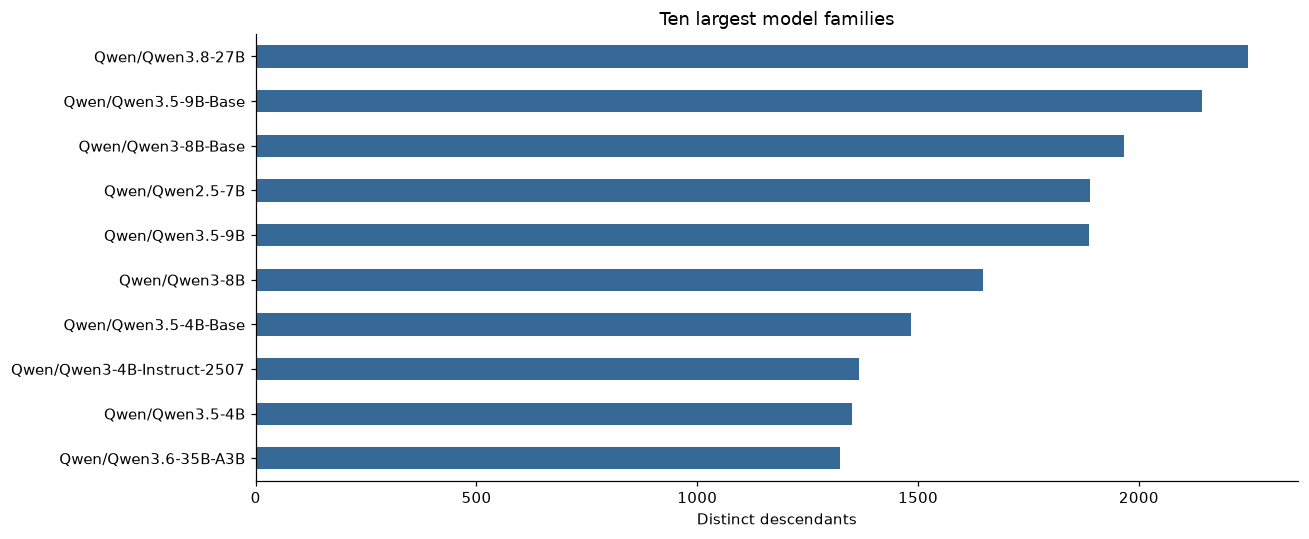

In [4]:
families = pd.DataFrame(
    read(
        "MATCH (m:Model) WHERE m.descendant_count IS NOT NULL "
        "RETURN m.id AS model, m.descendant_count AS descendants "
        "ORDER BY descendants DESC, model LIMIT $limit",
        limit=10,
    )
)
fig, axis = plt.subplots(figsize=(12, 5))
families.iloc[::-1].plot.barh(x="model", y="descendants", ax=axis, legend=False, color="#376996")
axis.set(title="Ten largest model families", xlabel="Distinct descendants", ylabel="")
fig.tight_layout()
plt.show()


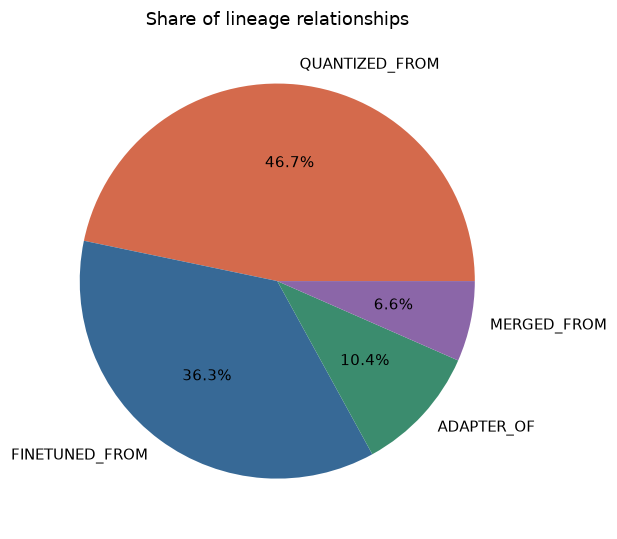

In [5]:
relation_colors = {
    "FINETUNED_FROM": "#376996",
    "ADAPTER_OF": "#3b8c6e",
    "QUANTIZED_FROM": "#d46a4c",
    "MERGED_FROM": "#8b66a8",
}
lineage_types = pd.DataFrame(
    read(
        "MATCH ()-[r]->() WHERE type(r) IN $relations "
        "RETURN type(r) AS relation, count(*) AS links ORDER BY links DESC, relation LIMIT $limit",
        relations=list(relation_colors),
        limit=4,
    )
)
fig, axis = plt.subplots(figsize=(8, 5))
axis.pie(
    lineage_types["links"],
    labels=lineage_types["relation"],
    autopct="%1.1f%%",
    colors=[relation_colors[kind] for kind in lineage_types["relation"]],
)
axis.set_title("Share of lineage relationships")
fig.tight_layout()
plt.show()


## 4. A small Mistral family tree

The API selects the 12 most downloaded descendants within two hops of
`mistralai/Mistral-7B-v0.1`. We then read their real graph paths and include
any connecting parent. This is a bounded sample, not the whole family.
Arrows point **from child to parent**, matching the stored relationships;
edge color shows the relation kind. Numbered labels identify the table below.

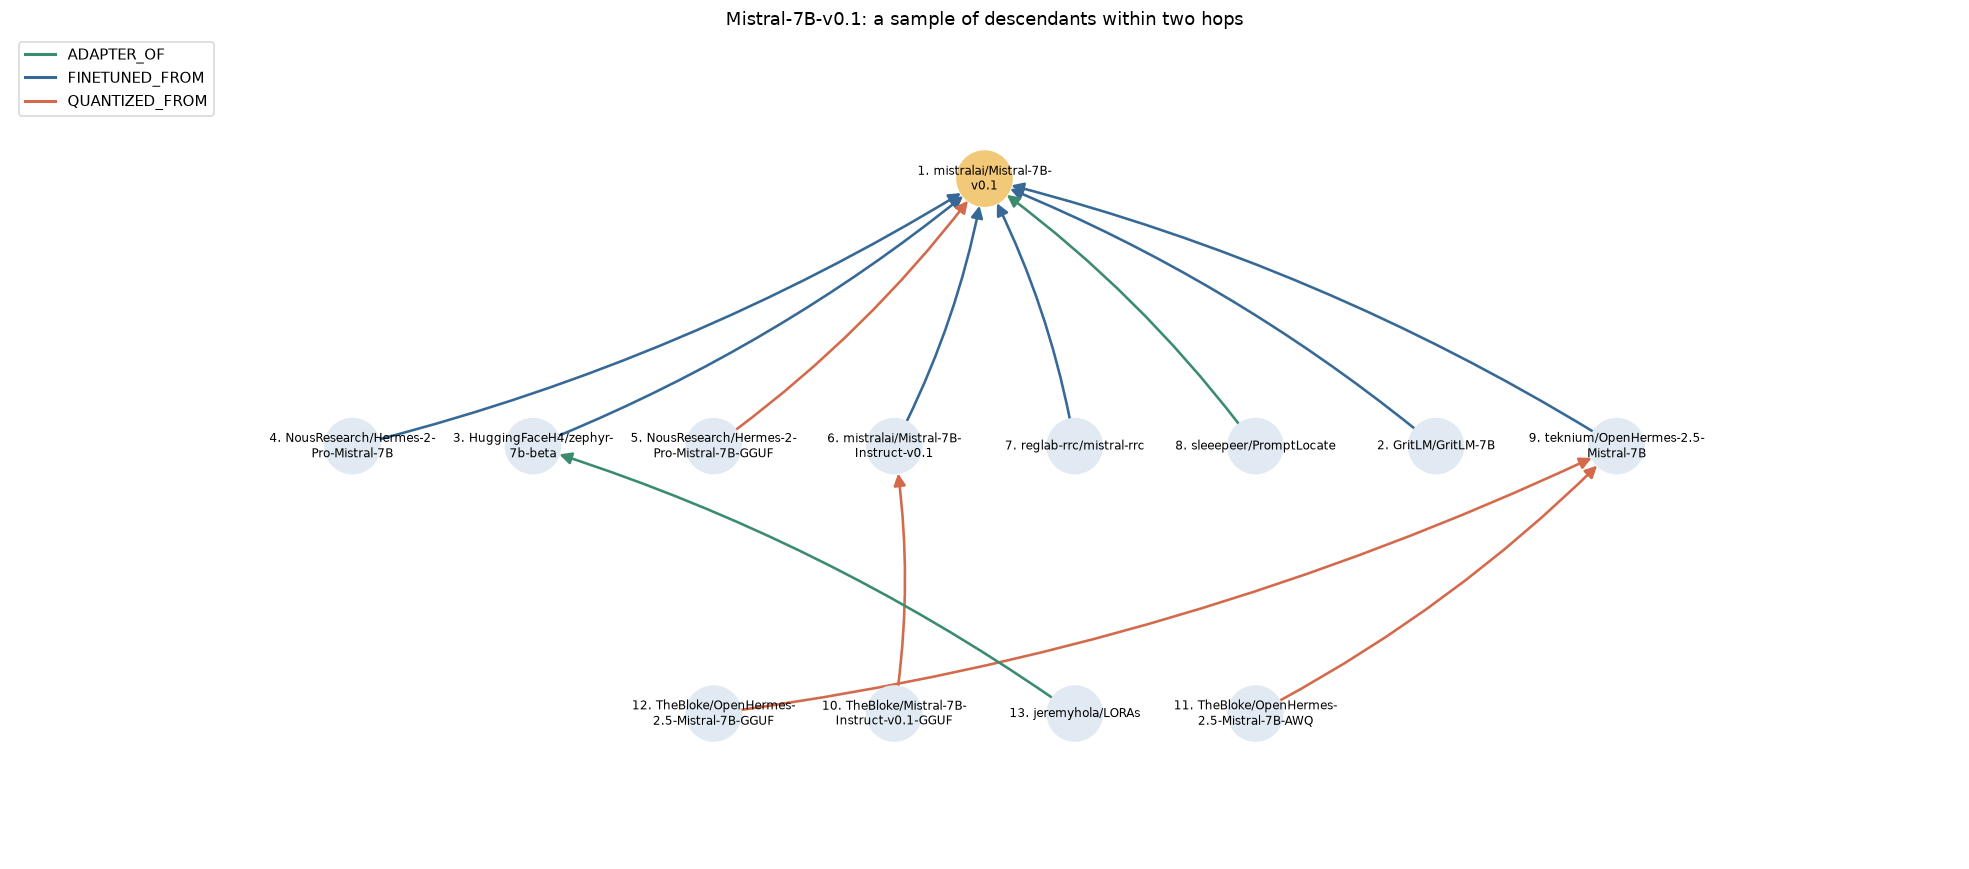

,number,model,distance from root
0,1,mistralai/Mistral-7B-v0.1,0
1,2,GritLM/GritLM-7B,1
2,3,HuggingFaceH4/zephyr-7b-beta,1
3,4,NousResearch/Hermes-2-Pro-Mistral-7B,1
4,5,NousResearch/Hermes-2-Pro-Mistral-7B-GGUF,1
5,6,mistralai/Mistral-7B-Instruct-v0.1,1
6,7,reglab-rrc/mistral-rrc,1
7,8,sleeepeer/PromptLocate,1
8,9,teknium/OpenHermes-2.5-Mistral-7B,1
9,10,TheBloke/Mistral-7B-Instruct-v0.1-GGUF,2


API sample: 12 descendants; drawing includes 13 nodes and 12 real edges.


In [6]:
import textwrap
from matplotlib.lines import Line2D

family_root = "mistralai/Mistral-7B-v0.1"
page = api(f"/models/{quote(family_root, safe='/')}/descendants", depth=2, limit=12)
selected = [item["model"]["id"] for item in page["items"]]
assert selected, "The full graph must contain descendants of the selected Mistral model."
paths = read(
    "MATCH p=(child:Model)-[:FINETUNED_FROM|ADAPTER_OF|QUANTIZED_FROM|MERGED_FROM*1..2]"
    "->(root:Model {id:$root}) WHERE child.id IN $ids "
    "RETURN [node IN nodes(p) | node.id] AS models, "
    "[rel IN relationships(p) | type(rel)] AS relations LIMIT $limit",
    root=family_root,
    ids=selected,
    limit=100,
)
tree = nx.MultiDiGraph()
for path in sorted(paths, key=lambda item: (item["models"], item["relations"])):
    for child, parent, kind in zip(path["models"], path["models"][1:], path["relations"]):
        tree.add_edge(child, parent, key=kind, relation=kind)
assert set(selected) <= set(tree.nodes), "Increase the bounded path sample if a selected model is missing."
levels = nx.single_source_shortest_path_length(tree.to_undirected(), family_root)
nx.set_node_attributes(tree, levels, "level")
positions = nx.multipartite_layout(tree, subset_key="level", align="horizontal")
positions = {node: (position[0], -position[1]) for node, position in positions.items()}
ordered = sorted(tree, key=lambda node: (levels[node], node))
labels = {node: f"{index}. " + "\n".join(textwrap.wrap(node, 23)) for index, node in enumerate(ordered, 1)}
colors = [relation_colors[kind] for _, _, kind in tree.edges(keys=True)]

fig, axis = plt.subplots(figsize=(18, 8))
nx.draw_networkx(
    tree,
    pos=positions,
    labels=labels,
    ax=axis,
    node_size=1300,
    node_color=["#f2c879" if node == family_root else "#e1eaf2" for node in tree],
    edge_color=colors,
    font_size=8,
    arrowsize=16,
    width=1.7,
    connectionstyle=["arc3,rad=0.08", "arc3,rad=-0.08"],
)
kinds = sorted({attributes["relation"] for _, _, attributes in tree.edges(data=True)})
axis.legend(
    handles=[Line2D([0], [0], color=relation_colors[kind], label=kind, lw=2) for kind in kinds], loc="upper left"
)
axis.set_title("Mistral-7B-v0.1: a sample of descendants within two hops")
axis.margins(0.2)
axis.axis("off")
fig.tight_layout()
plt.show()
display(
    pd.DataFrame(
        {
            "number": range(1, len(ordered) + 1),
            "model": ordered,
            "distance from root": [levels[node] for node in ordered],
        }
    )
)
print(
    f"API sample: {len(selected)} descendants; drawing includes {len(tree)} nodes and {tree.number_of_edges()} real edges."
)


## 5. Model licenses

Count licenses declared by Model nodes, not licenses used only by datasets.
We also ask the API about five popular models. Its verdict includes ancestor
restrictions within the configured depth; it is a derived, simplified result.
`needs_review` means information or a reviewed rule is missing, not permission.

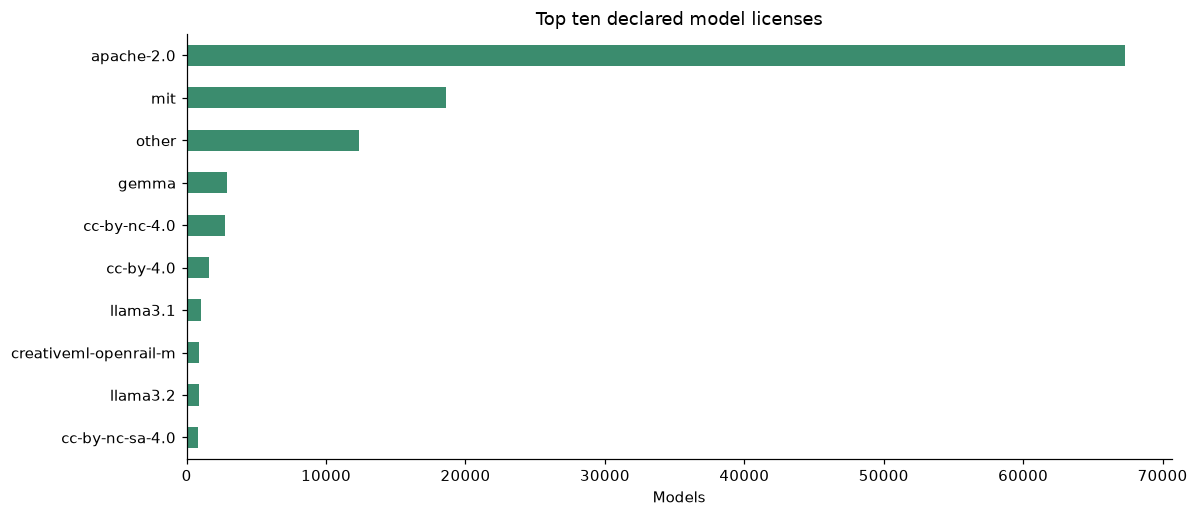

,model,declared license,verdict,incomplete lineage
0,sentence-transformers/all-MiniLM-L6-v2,apache-2.0,commercial_use_ok,False
1,cross-encoder/ms-marco-MiniLM-L6-v2,apache-2.0,commercial_use_ok,False
2,BAAI/bge-small-en-v1.5,mit,commercial_use_ok,False
3,google-bert/bert-base-uncased,apache-2.0,commercial_use_ok,False
4,sentence-transformers/paraphrase-multilingual-...,apache-2.0,commercial_use_ok,False


In [7]:
licenses = pd.DataFrame(
    read(
        "MATCH (m:Model)-[:HAS_LICENSE]->(license:License) "
        "RETURN license.id AS license, count(DISTINCT m) AS models "
        "ORDER BY models DESC, license LIMIT $limit",
        limit=10,
    )
)
fig, axis = plt.subplots(figsize=(11, 4.8))
licenses.iloc[::-1].plot.barh(x="license", y="models", ax=axis, color="#3b8c6e", legend=False)
axis.set(title="Top ten declared model licenses", xlabel="Models", ylabel="")
fig.tight_layout()
plt.show()

popular = read(
    "MATCH (m:Model) WHERE NOT m:Unlisted RETURN m.id AS id, m.downloads AS downloads "
    "ORDER BY downloads DESC, id LIMIT $limit",
    limit=5,
)
verdicts = []
for model in popular:
    verdict = api(f"/models/{quote(model['id'], safe='/')}/license-check", depth=6)
    own = verdict.get("declared_license") or {}
    verdicts.append(
        {
            "model": model["id"],
            "declared license": own.get("id"),
            "verdict": verdict["verdict"],
            "incomplete lineage": verdict["incomplete_lineage"],
        }
    )
display(pd.DataFrame(verdicts))


## 6. Dataset cards: the second source

The denominator is **distinct cited Dataset nodes**, not every dataset on the Hub.
`Dataset.listed` says whether a matching card was found. A missing card and a
missing license rule are both gaps in our knowledge.

A dataset with several licenses counts once as non-commercial if **any** linked
license has `commercial_use = false`. Other classified rules include conditional
ones; they do not prove unrestricted use. Unknown rules stay in a separate group.
These results depend on the rule table used when the graph was loaded.
Dataset-license evidence is shown separately from the model-ancestry verdicts above.

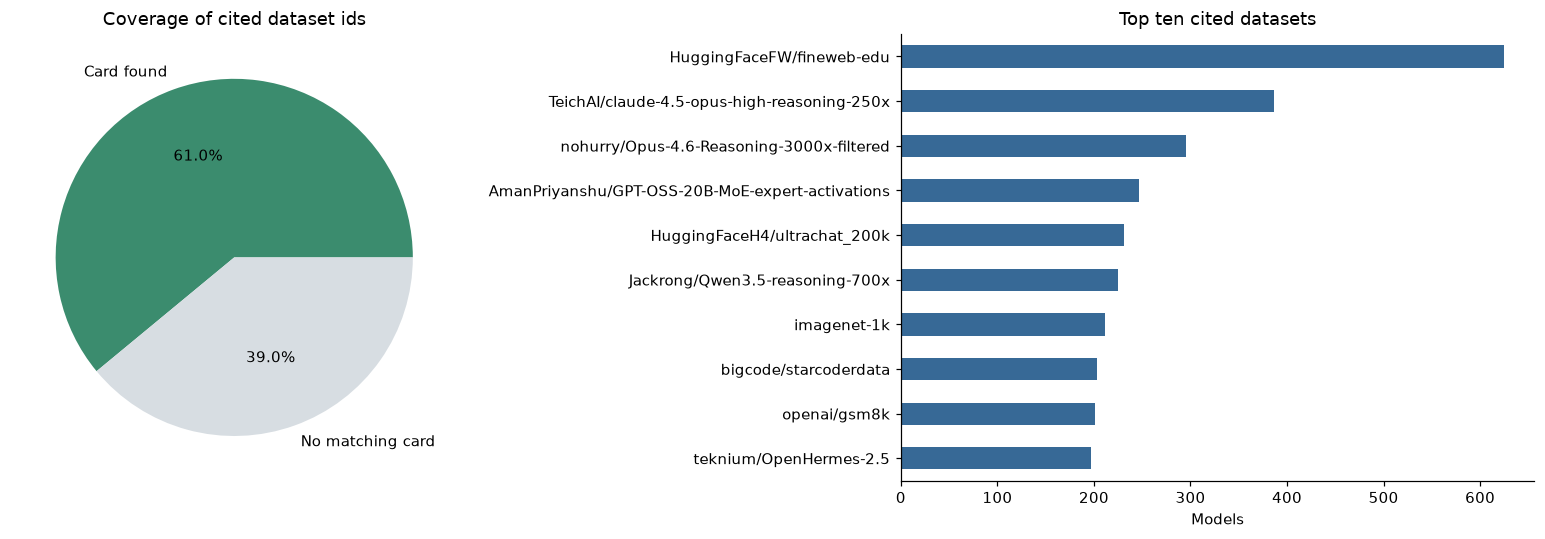

,cited,listing_known,with_card,noncommercial,unknown_license
0,15495,15495,9451,303,11172


In [8]:
dataset_summary = read(
    "MATCH (dataset:Dataset) WHERE EXISTS { MATCH (:Model)-[:TRAINED_ON]->(dataset) } "
    "WITH dataset, EXISTS { MATCH (dataset)-[:HAS_LICENSE]->(license:License) "
    "WHERE license.commercial_use = $noncommercial } AS noncommercial, "
    "EXISTS { MATCH (dataset)-[:HAS_LICENSE]->(license:License) "
    "WHERE license.commercial_use IS NOT NULL } AS classified "
    "RETURN count(dataset) AS cited, count(dataset.listed) AS listing_known, "
    "sum(CASE WHEN dataset.listed = $listed THEN 1 ELSE 0 END) AS with_card, "
    "sum(CASE WHEN noncommercial THEN 1 ELSE 0 END) AS noncommercial, "
    "sum(CASE WHEN NOT classified THEN 1 ELSE 0 END) AS unknown_license LIMIT $limit",
    noncommercial=False,
    listed=True,
    limit=1,
)[0]
assert dataset_summary["cited"] > 0
assert (
    dataset_summary["listing_known"] == dataset_summary["cited"]
), "Dataset.listed is missing. Load both sources with PR #5's ETL before running this section."
assert dataset_summary["with_card"] > 0, "Download dataset_cards and reload the full graph."
top_datasets = pd.DataFrame(
    read(
        "MATCH (m:Model)-[:TRAINED_ON]->(dataset:Dataset) "
        "RETURN dataset.id AS dataset, count(DISTINCT m) AS models "
        "ORDER BY models DESC, dataset LIMIT $limit",
        limit=10,
    )
)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].pie(
    [dataset_summary["with_card"], dataset_summary["cited"] - dataset_summary["with_card"]],
    labels=["Card found", "No matching card"],
    autopct="%1.1f%%",
    colors=["#3b8c6e", "#d7dde2"],
)
axes[0].set_title("Coverage of cited dataset ids")
top_datasets.iloc[::-1].plot.barh(x="dataset", y="models", ax=axes[1], color="#376996", legend=False)
axes[1].set(title="Top ten cited datasets", xlabel="Models", ylabel="")
fig.tight_layout()
plt.show()
display(pd.DataFrame([dataset_summary]))


In [9]:
cited = dataset_summary["cited"]
noncommercial = dataset_summary["noncommercial"]
unknown = dataset_summary["unknown_license"]
license_groups = pd.DataFrame(
    {
        "dataset license status": [
            "At least one non-commercial rule",
            "Other classified rule",
            "No classified license rule",
        ],
        "datasets": [noncommercial, cited - noncommercial - unknown, unknown],
    }
)
license_groups["share of cited dataset ids"] = license_groups["datasets"] / cited
display(license_groups.style.format({"share of cited dataset ids": "{:.2%}"}))
print(f"{noncommercial:,} of {cited:,} cited dataset ids ({noncommercial / cited:.2%}) have a non-commercial rule.")
print("Unknown licenses are not counted as commercially usable.")


,dataset license status,datasets,share of cited dataset ids
0,At least one non-commercial rule,303,1.96%
1,Other classified rule,4020,25.94%
2,No classified license rule,11172,72.10%


303 of 15,495 cited dataset ids (1.96%) have a non-commercial rule.
Unknown licenses are not counted as commercially usable.


In [10]:
driver.close()
http.close()
elapsed = perf_counter() - started
print(f"Analysis completed in {elapsed:.1f} seconds; connections closed.")
assert elapsed < 120, "The demo should finish in less than two minutes on the prepared stack."


Analysis completed in 6.8 seconds; connections closed.


## 7. What we learned

1. **Most models have short ancestry chains.** In this graph, 99.42% of models with a depth value have a longest parent chain of five hops or less. Longer chains still exist, so a small traversal limit is useful for exploration but can miss some ancestors.

2. **One base model supports several kinds of reuse.** The Mistral example shows different relation types within two hops. Our sample contains 12 descendants and draws 13 nodes with 12 real edges. It helps explain the family, but it is only a small sample of its descendants.

3. **Common licenses do not describe every model.** Apache-2.0 is the most common declared model license in the chart. All five popular models we checked receive `commercial_use_ok` under the loaded rules. This small sample does not establish the result for other models, and the model-ancestry verdict does not include the separate dataset analysis in section 6.

4. **The second source adds useful information but leaves gaps.** We found cards for 9,451 of the 15,495 cited dataset IDs, or 61.0%. The other 39.0% have no matching card in this snapshot. A model citing a dataset does not mean we have enough information about that dataset.

5. **Missing license information is the main limit of the dataset analysis.** The loaded rules identify 303 cited datasets (1.96%) with at least one non-commercial license rule, while 11,172 have no classified license rule. We cannot treat the remaining datasets as commercially usable just because they are outside the non-commercial group. These counts describe this snapshot and its rule table.